# 00 · Start here — what does a classification guess look like?

**Day 3 slides** 3 and 6

### The problem

A loan has already been made. Its record says whether it defaulted within 12 months. What would it mean to guess that yes-or-no answer beforehand?

### What we’re doing

Take eight example loans, apply a simple flagging rule and put the flags beside the recorded answers.

### Why we’re doing it

This makes the difference between a score, a decision and an actual answer visible before we fit a model.

Read the text above a code cell, then click the cell and press
**Shift + Enter**. Run from the top. The files contain synthetic course data.

### Day 3 teaching order

| Course start | Notebook |
|---|---|
| 09:10 | [D3.1 · Compare scores, flags, mistakes and cutoffs](D3.1_Classification_Metrics_and_Thresholds.ipynb) |
| 10:05 | [L3.1 · Compare logistic regression and KNN](L3.1_Credit_Default_Walkthrough.ipynb) |
| 13:00 | [D3.2 · See groups move and a tree pick a question](D3.2_Inside_Clustering_and_Trees.ipynb) |
| 13:35 | [L3.2 · Read and explain customer groups](L3.2_Customer_Segmentation_Walkthrough.ipynb) |
| 14:20 | [L3.3 · Build and check a small daily review list](L3.3_Fraud_Trees_and_Forests_Walkthrough.ipynb) |
| 15:55 | [L3.4 · Churn classification, gains and deciding whom to call](L3.4_Churn_Classification_Walkthrough.ipynb) |

Use this warm-up before D3.1. Each notebook starts with its own setup. If training and testing are new to the group, revisit [Day 2’s first ML workflow](../../Day2/Basic_Demos/00_Start_Here_Your_First_ML_Workflow.ipynb).

**Optional after churn** [Slide 22 · When a tree predicts a number](Optional_Slide22_Regression_Tree_Contrast.ipynb).

### How this follows the trainer guide

| Trainer guide cards | Class focus |
|---|---|
| 1–35 | Classification. Start with yes or no, then discuss chances, logistic regression, KNN, mistakes, cutoffs, class imbalance and calibration. |
| 36–50 | Clustering. Find groups in customer behaviour with k-means and hierarchical clustering. |
| 51–69 | Classification trees and ensembles. Talk through one tree question, then learn how forests and boosting rank a small fraud review queue. |
| 70–73 and 77 | Churn classification. Compare methods and decide whom to call using lift, gains and expected value. |
| 74–76 | Optional comparison. See what changes when a tree’s answer is a number. |


### Three terms students will hear

- **Classification** guesses a label, such as default or no default.
- **Probability** is a number from zero to one that represents a chance.
  A cutoff turns the chance into a label or a review flag.
- **Logistic regression** is the name of a method we use to estimate
  the chance of a class. In D3.1 the final answer is a label.

## Setup · Open the data

Read the debt burden ratio and whether the loan defaulted. We deliberately pick four defaults and four non-defaults so both labels are visible. The eight rows do not show the usual rate in the full file. Run this cell as written. The import lines make the tools
available. The folder lines find the supplied data.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from pathlib import Path

here = Path.cwd()
data = next((folder / "data" for folder in (here, *here.parents)
             if (folder / "data" / "loan_applications.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

columns = ["debt_burden_ratio", "default_12m"]
loans = pd.read_csv(data / "loan_applications.csv", usecols=columns).dropna()
paid = loans[loans["default_12m"] == 0].sample(4, random_state=42)
defaulted = loans[loans["default_12m"] == 1].sample(4, random_state=42)
examples = pd.concat([paid, defaulted]).sort_values("debt_burden_ratio").reset_index(drop=True)
examples

,debt_burden_ratio,default_12m
0,0.2785,0
1,0.2964,1
2,0.3273,0
3,0.3667,1
4,0.3734,0
5,0.5000,0
6,0.5000,1
7,0.5000,1


## 1 · Make a guess from one clue

**What we’re doing.** Flag a loan when its debt payments are at least 40% of income in this classroom rule.

**Why.** Classification means guessing a label. We can see how a rule turns a number into a yes-or-no guess.

**Look for.** The first column is the clue, the next column is the recorded answer and the flag is our guess. The ratio is a share of income. It is not a probability of default.

In [2]:
cutoff = 0.40
examples["flag_for_review"] = (examples["debt_burden_ratio"] >= cutoff).astype(int)
examples

,debt_burden_ratio,default_12m,flag_for_review
0,0.2785,0,0
1,0.2964,1,0
2,0.3273,0,0
3,0.3667,1,0
4,0.3734,0,0
5,0.5000,0,1
6,0.5000,1,1
7,0.5000,1,1


## 2 · Match the guesses to what happened

**What we’re doing.** Put the guesses in a four-box chart. Rows show what actually happened and columns show what we guessed.

**Why.** We want to see caught defaults, missed defaults and cases flagged unnecessarily. Those mistakes have different effects.

**Look for.** Top left is a correct clear, top right is an extra flag, bottom left is a missed default, and bottom right is a caught default.

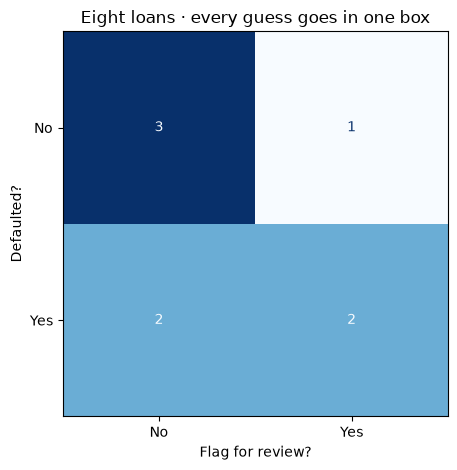

In [3]:
actual = examples["default_12m"]
guessed = examples["flag_for_review"]
ax = ConfusionMatrixDisplay.from_predictions(
    actual, guessed, labels=[0, 1], display_labels=["No", "Yes"],
    cmap="Blues", colorbar=False,
).ax_
ax.set(xlabel="Flag for review?", ylabel="Defaulted?", title="Eight loans · every guess goes in one box")
plt.tight_layout()
plt.show()

## 3 · Read two questions from the chart

**What we’re doing.** Count the defaults we caught, the flags we made and all the defaults in the group.

**Why.** Precision asks how many flags were right. Recall asks how many actual defaults we caught.

**Look for.** Read each question before reading its result. Changing the cutoff can change both.

In [4]:
caught = ((actual == 1) & (guessed == 1)).sum()
flags = guessed.sum()
defaults = actual.sum()
print(f"Precision · caught out of flagged: {caught} of {flags}")
print(f"Recall · caught out of actual defaults: {caught} of {defaults}")

Precision · caught out of flagged: 2 of 3
Recall · caught out of actual defaults: 2 of 4


### Your turn

Change the cutoff from 0.40 to 0.30. Run cells 1–3 again. Did you flag more loans? Next open [D3.1 · Scores, flags and mistakes](D3.1_Classification_Metrics_and_Thresholds.ipynb).